In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Problem Set 1: Simulating Customer Clicks
# Using a Bernoulli Random Variable
# ============================================================

# Given probability
p = 0.30

# Number of customers
sample_size = 20


# ============================================================
# Step 1: Identify the Random Variable
# ============================================================

# X = 1 -> Customer clicks
# X = 0 -> Customer does not click
# Possible values of X = {0, 1}
# X is a discrete random variable
# X follows Bernoulli distribution

print("Random Variable:")
print("X = 1 : Customer clicks")
print("X = 0 : Customer does not click")
print("Possible values of X : 0, 1")
print("Distribution : Bernoulli")
print("Probability of click p =", p)


# ============================================================
# Step 2: Theoretical PMF
# ============================================================

# Bernoulli PMF:
# P(X = x) = p^x * (1-p)^(1-x)

theoretical_pmf = {
    0: 1 - p,
    1: p
}

print("\nTheoretical PMF:")
print("P(X=0) =", theoretical_pmf[0])
print("P(X=1) =", theoretical_pmf[1])


# ============================================================
# Step 3: Generate outcomes for 20 customers
# ============================================================

samples = np.random.binomial(
    n=1,
    p=p,
    size=sample_size
)

print("\nGenerated observations:")
print(samples)

print("\nNumber of observations generated:", len(samples))


# ============================================================
# Step 4: Count clicks and non-clicks
# ============================================================

number_of_clicks = np.sum(samples == 1)

number_of_non_clicks = np.sum(samples == 0)

print("\nNumber of clicks:", number_of_clicks)
print("Number of non-clicks:", number_of_non_clicks)

print("Total customers:",
      number_of_clicks + number_of_non_clicks)


# ============================================================
# Step 5: Calculate Empirical PMF
# ============================================================

empirical_pmf = {
    0: number_of_non_clicks / sample_size,
    1: number_of_clicks / sample_size
}

print("\nEmpirical PMF:")
print("P(X=0) =", empirical_pmf[0])
print("P(X=1) =", empirical_pmf[1])


# ============================================================
# Step 6: Compare Empirical and Theoretical PMFs
# ============================================================

pmf_comparison = pd.DataFrame({
    "Outcome": ["X = 0", "X = 1"],
    "Theoretical Probability": [
        theoretical_pmf[0],
        theoretical_pmf[1]
    ],
    "Empirical Probability": [
        empirical_pmf[0],
        empirical_pmf[1]
    ]
})

pmf_comparison

Random Variable:
X = 1 : Customer clicks
X = 0 : Customer does not click
Possible values of X : 0, 1
Distribution : Bernoulli
Probability of click p = 0.3

Theoretical PMF:
P(X=0) = 0.7
P(X=1) = 0.3

Generated observations:
[1 1 0 0 0 0 1 0 1 0 1 0 0 0 0 0 1 0 0 0]

Number of observations generated: 20

Number of clicks: 6
Number of non-clicks: 14
Total customers: 20

Empirical PMF:
P(X=0) = 0.7
P(X=1) = 0.3


,Outcome,Theoretical Probability,Empirical Probability
0,X = 0,0.7,0.7
1,X = 1,0.3,0.3


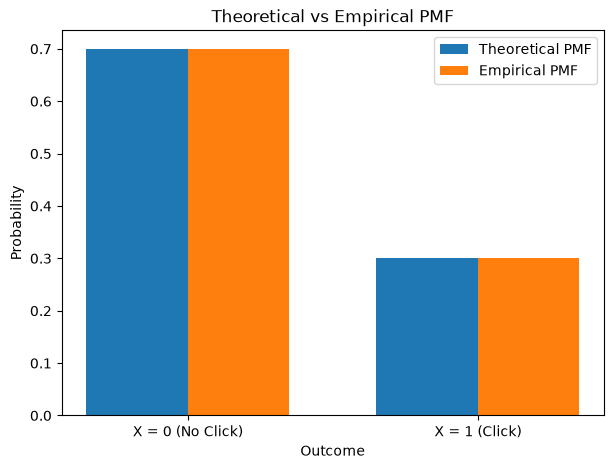

In [3]:
# ============================================================
# Step 7: Plot Empirical and Theoretical PMFs
# ============================================================

x = np.array([0, 1])

theoretical_values = np.array([
    theoretical_pmf[0],
    theoretical_pmf[1]
])

empirical_values = np.array([
    empirical_pmf[0],
    empirical_pmf[1]
])

width = 0.35

plt.figure(figsize=(7, 5))

plt.bar(
    x - width / 2,
    theoretical_values,
    width,
    label="Theoretical PMF"
)

plt.bar(
    x + width / 2,
    empirical_values,
    width,
    label="Empirical PMF"
)

plt.xlabel("Outcome")
plt.ylabel("Probability")
plt.title("Theoretical vs Empirical PMF")
plt.xticks([0, 1], ["X = 0 (No Click)", "X = 1 (Click)"])
plt.legend()

plt.show()

In [4]:
# ============================================================
# Step 8: Theoretical Expectation
# ============================================================

theoretical_mean = p

print("Theoretical Expectation =", theoretical_mean)

Theoretical Expectation = 0.3


In [5]:
# ============================================================
# Step 9: Empirical Expectation
# ============================================================

empirical_mean = np.mean(samples)

print("Empirical Expectation =", empirical_mean)

Empirical Expectation = 0.3


In [6]:
# ============================================================
# Step 10: Theoretical Variance
# ============================================================

theoretical_variance = p * (1 - p)

print("Theoretical Variance =", theoretical_variance)

Theoretical Variance = 0.21


In [7]:
# ============================================================
# Step 11: Empirical Variance
# ============================================================

empirical_variance = np.var(samples)

print("Empirical Variance =", empirical_variance)

Empirical Variance = 0.20999999999999996


In [8]:
# ============================================================
# Step 12: Final Result Table
# ============================================================

result_table = pd.DataFrame({
    "Measure": [
        "P(X=0)",
        "P(X=1)",
        "Expectation",
        "Variance"
    ],

    "Theoretical Value": [
        theoretical_pmf[0],
        theoretical_pmf[1],
        theoretical_mean,
        theoretical_variance
    ],

    "Empirical Value": [
        empirical_pmf[0],
        empirical_pmf[1],
        empirical_mean,
        empirical_variance
    ]
})

result_table["Absolute Difference"] = (
    abs(
        result_table["Theoretical Value"]
        - result_table["Empirical Value"]
    )
)

result_table

,Measure,Theoretical Value,Empirical Value,Absolute Difference
0,P(X=0),0.70,0.70,0.000000e+00
1,P(X=1),0.30,0.30,0.000000e+00
2,Expectation,0.30,0.30,0.000000e+00
3,Variance,0.21,0.21,2.775558e-17


In [9]:
# ============================================================
# Step 13: Effect of Sample Size
# ============================================================

sample_sizes = [10, 100, 1000, 10000]

results = []

for n in sample_sizes:

    data = np.random.binomial(
        n=1,
        p=p,
        size=n
    )

    number_of_zeros = np.sum(data == 0)
    number_of_ones = np.sum(data == 1)

    empirical_p0 = number_of_zeros / n
    empirical_p1 = number_of_ones / n

    empirical_mean = np.mean(data)
    empirical_variance = np.var(data)

    results.append({
        "Sample Size": n,
        "Empirical P(X=0)": empirical_p0,
        "Empirical P(X=1)": empirical_p1,
        "Empirical Mean": empirical_mean,
        "Empirical Variance": empirical_variance
    })


sample_size_table = pd.DataFrame(results)

sample_size_table

,Sample Size,Empirical P(X=0),Empirical P(X=1),Empirical Mean,Empirical Variance
0,10,0.9000,0.1000,0.1000,0.090000
1,100,0.7000,0.3000,0.3000,0.210000
2,1000,0.7040,0.2960,0.2960,0.208384
3,10000,0.6951,0.3049,0.3049,0.211936
